# Generating a Bode Plot for the Cart/Pendulum System

v. 1.0.1

In [11]:
import matplotlib.pyplot as plt
import numpy as np
import control
from numpy import sin, cos, tan, pi
from control import TransferFunction as TF

## Overview

In this lab, you will give a swept sine input to your cart/pendulum system.  You will then use that data to generate a Bode plot for the cart/pendulum system.  The Bode plot will eventually guide you to a better TF model for the system.

## Main Steps/Outline

- generate a Bode plot for your assumed pendulum transfer function
    - generate the expected result first so you know what a "good" Bode plot looks like
- collect swept sine data for the cart/pendulum system
- generate a Bode plot from the swept sine data
    - you may need to write some Python code to clean up the phase portion of the Bode plot
- repeat data collection and Bode generation for the cart/pendulum
    - your first attempt will probably not lead to a "good" Bode plot
- overlay the model and experimental Bode plots for the system

## Generating a Bode Plot

There are two different processes for generating a Bode plot depending on whether we already know the transfer function or we are using experimental data to create the Bode plot.  These two processes have their own methods for finding the frequency vector `f` and the complex vector `Gjw`.  Once we have `f` and `Gjw`, the final calculations and actual plotting steps are the same for both processes

### Generating a Bode Plot from a Transfer Function

If we already know the transfer function $G(s)$ and want to generate its Bode plot in Python, we need to do the following:
- generate a frequency array along with arrays for $\omega$ and $s$
- evaluate the transfer function at each value of $s=j\omega$

```
f = np.logspace(-2,2,1000)
w = 2*np.pi*f
s = 1j*w
Gjw = G(s)
```

#### `logspace` explained

Bode plots generally have a wide frequency range, so we plot them using a logscale on the `x` (frequency) axis.  So, we want our frequency array to have log spacing.  The code

```
f = np.logspace(-2,2,1000)
```

will create an array `f` from $10^{-2}$ to $10^2$ with 1000 points that are logarithmically spaced.

Once we have `f` and `Gjw` we are ready for the final calculations and plotting.

### Generating a Bode Plot from Experimental Data

If we have time-domain data for the input and output of a system and want to generate the corresponding Bode plot, we need to do the following:

- find the frequency array from the time array
- find $G(j\omega)$ using `fft`

#### Find the frequency array from the time array

When working with experimental data, we need to calculate the frequency array that corresponds to our time domain data.  If data is collected for a certain length of time $T$ with a certain sampling frequency $f_s$, then

$$dt = \frac{1}{f_s}$$

and

$$df = \frac{1}{T}$$

**Note:** It should work out that $T$ is the same at `stop_t`.

We ran our tests at 500 Hz, so that $f_s = 500$ Hz and $dt = 0.002$ seconds.

- $f_s$ is controlled by the Arduino timer settings.

Our time vector will be

$$t = \left[0, dt, 2 \cdot dt, 3 \cdot dt, ..., T-dt\right]$$

And the frequency vector will be

$$freq = \left[0, df, 2 \cdot df, 3 \cdot df, ..., f_s-df\right]$$

The easiest way to find the frequency vector in Python is to first calculate $df$.  Then, create an `nvect` based on the length of `t`:

```
dt = t[1]-t[0]
T = t.max() + dt
N = len(t)
nvect = np.arange(N)
df = 1/T
```

Then, the frequency vector will be

```
freq = df*nvect
```

### Note: Milliseconds are probably bad

By default, the Arduino code will output time in milliseconds.  This will mean you need to divide by 1000 before finding the frequency vector:

```
t = t_ms/1000
```

### Finding $G(j\omega)$ using the FFT

We will use the fast Fourier transform or fft to find $G(j\omega)$.  We will use the `fft` algorithm provided by the `numpy` module (`numpy.fft.fft`).  To avoid typing all of that, we will import it as `fft`:

In [12]:
from numpy.fft import fft

We don't have time to go into too many details about it right now.  The main thing you need to know is that:

$$G(j\omega) = \frac{\texttt{fft(output)}}{\texttt{fft(input)}}$$

or

```
Gjw = fft(y)/fft(u)
```

where `y` is the output of the system and `u` is the input.

## Final Bode Calculations and Plotting

The two processes described above both lead to the frequency array `f` and the complex array `Gjw`.  Once we have those, we are ready to calculate the dB magnitude and phase.  From there, we are ready to generate the actual Bode plot.

### Calculating dB Magnitude and Phase

```
M = np.abs(Gjw)
dB_mag = 20*np.log10(M)
phase = np.angle(Gjw,1)#<-- note that the ,1 means degrees
```

### Generating a Bode Plot

The magnitude and phase portions of the Bode plot need to be drawn on separate axes that are vertically stacked.  We use a log axis on the `x` or frequency axis:

```
plt.figure()
plt.subplot(211)#<-- 2 rows, 1 column, plot #1
plt.semilogx(f, dB_mag)
plt.ylabel('dB Mag.')
plt.subplot(212)#<-- plot #2
plt.semilogx(f, phase)
plt.ylabel('Phase (deg.)')
plt.xlabel('Freq. (Hz)')
```

## Bode Example for RC Transfer Function

Here is an example of generating a Bode plot for a simple transfer function:

In [13]:
p = 3*2*pi
G = TF(p,[1,p])
f = np.logspace(-2,2,1000)
w = 2*pi*f
s = 1j*w
Gjw = G(s)

In [14]:
M = np.abs(Gjw)
dB_mag = 20*np.log10(M)
phase = np.angle(Gjw,1)

Text(0.5, 0, 'Freq. (Hz)')

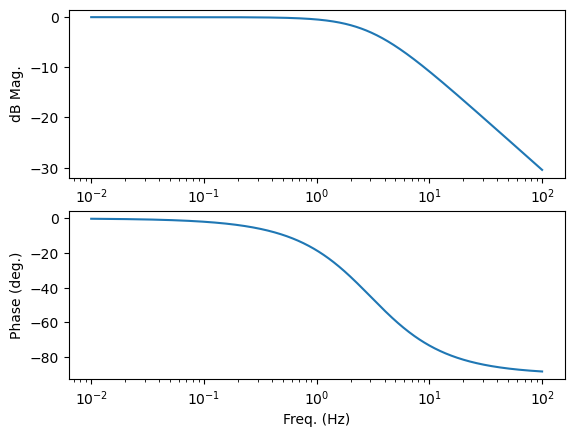

In [15]:
plt.figure()
plt.subplot(211)
plt.semilogx(f, dB_mag)
plt.ylabel('dB Mag.')
plt.subplot(212)
plt.semilogx(f, phase)
plt.ylabel('Phase (deg.)')
plt.xlabel('Freq. (Hz)')

## Block Diagram

There is only one change to your block diagram from last week: the input will now be a swept sine rather than a fixed sine.  The actuator, sensor, and plant are the same as last week.

## Notes on "Good" Swept Sine Data

- a swept sine test probably takes 30-60 seconds
- you will likely need some trial and error to find good swept sine parameters:
    - amplitude
    - slope
    - `stop_t`
    - `dead_time`
        - `dead_time` is how long at record data with no input at the end of the test to let the vibration die out
        - the input turns off at `stop_t - dead_time`
            - note that if `dead_time` is greater than `stop_t`, the input will never turn on
- your maximum frequency will be `slope*stop_t`
    - make sure that the maximum frequency is several times higher than the resonant frequency of the pendulum
- good `fft` data should start and stop at the same value (probably zero)
    - the `fft` algorithm assumes that the data could be copied and pasted an infinite number of times
    - if the data doesn't start and stop at the same value, there will be a jump when the pasted section starts
    - you need to collect data long enough for the pendulum to stop swinging and/or have a high maximum input frequency so that the pendulum essentially doesn't respond (near zero amplitude)

### Example of "ok" swept sine data

Below is an example of fairly decent swept sine data.  The output amplitude probably gets too large, so the input amplitude is probably also too large.  Note that `dead_time` for this test was 5 seconds, so the input goes to zero 5 seconds before the test ends and the pendulum stops moving before the test ends.

<img src="figs/example_swept_sine_data.png" width=600px>

## Overlay the Model and Experimental Bode Plots

Once you have a "good" Bode plot from your experimental data, overlay it with the Bode plot from your transfer function model.  See if you can get better agreement by adjusting your parameters.  

## Comprehension Question

- what are the differences between your experimental Bode plot and then one from your transfer function model?
- what do you think it would take to get your model Bode plot to match the one from the data better?